In [1]:
import json
import gc

from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from tqdm import tqdm

In [2]:
DATA_PATH = Path("data")

# Exploratory Data Analysis (EDA)

## Initial example of data load (changed to Pandas)

In [3]:
# split = DATA_PATH / "competition" / "train"
# content_list = [
#     pd.read_parquet(f)
#     .head(1)
#     for f in sorted(split.glob("impressions/part-*.parquet"))
# ]
# feed = pd.concat(content_list, axis=0, ignore_index=True)
# del content_list

In [4]:
# embedding_dir = split / "item_embeddings"
# meta = json.loads((embedding_dir / "data.meta").read_text())
# embeddings = np.memmap(
#     embedding_dir / "data.memmap",
#     dtype=meta["dtype"],
#     mode="r",
#     shape=tuple(meta["shape"]),
#     order=meta["order"],
# )

In [5]:
# arr_list = []
# for _, arr in feed["item_id__embedding_idx"].items():
#     arr_list.append(np.pad(np.asarray(arr, dtype=np.int64), (0, 512 - len(arr)), constant_values=-1, mode='constant'))
# indices = np.asarray(arr_list)
# del arr_list

# candidate_vectors = np.zeros((indices.size, 128), dtype=np.float32)
# candidate_vectors[(indices >= 0).flatten()] = embeddings[indices[indices >= 0]].astype(np.float32)
# user_vector = np.asarray([np.asarray(arr, dtype=np.float32) for _, arr in feed["user_embedding"].items()])

## Example of submit

In [6]:
submit_ex_df = pd.read_parquet(DATA_PATH / "sample_submission.parquet").head()
submit_ex_df

,feed_id,item_id,score
0,27586,50639592,0.0
1,27586,77707727,0.0
2,27586,110441326,0.0
3,27586,99506506,0.0
4,27586,45124951,0.0


## Look at the binary features

In [7]:
BIN_FEATURES = ["f1", "f2", "f3", "f4", "f5"]

In [8]:
split = DATA_PATH / "competition" / "train"
content_list = [
    pd.read_parquet(f, columns=BIN_FEATURES + ["item_id"])
    for f in sorted(split.glob("impressions/part-*.parquet"))
]
df = pd.concat(content_list, axis=0, ignore_index=True)
del content_list

  1%|▍                                                  | 28594/3151208 [00:00<00:21, 143147.24it/s]

Found different values for "f1" for item 68574619: old one is 0.3529638946056366 and new one is 0.322571724653244


100%|█████████████████████████████████████████████████| 3151208/3151208 [00:23<00:00, 133140.60it/s]


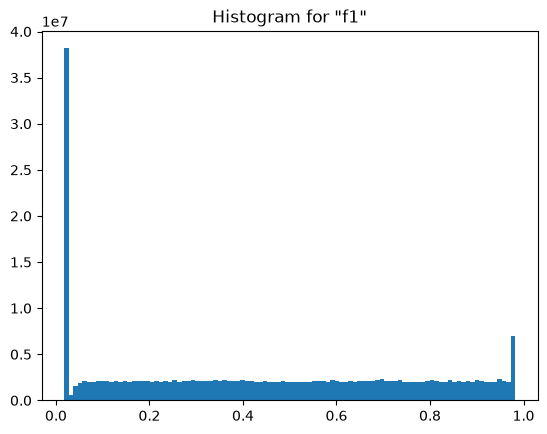

  1%|▍                                                  | 26611/3151208 [00:00<00:23, 131073.16it/s]

Found different values for "f2" for item 68574619: old one is 0.9466820955276489 and new one is 0.4157044291496277


100%|█████████████████████████████████████████████████| 3151208/3151208 [00:24<00:00, 130756.73it/s]


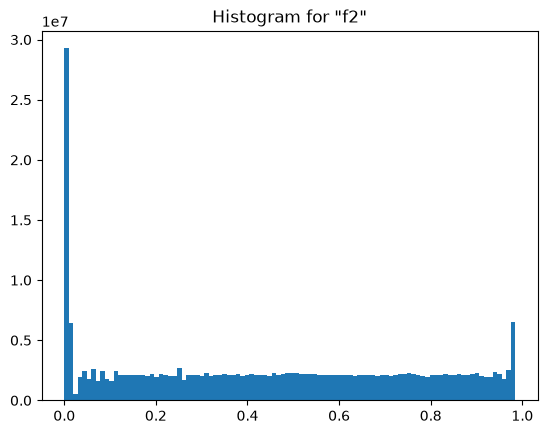

  1%|▍                                                  | 27030/3151208 [00:00<00:23, 132508.26it/s]

Found different values for "f3" for item 68574619: old one is 0.24121662974357605 and new one is 0.2751043736934662


100%|█████████████████████████████████████████████████| 3151208/3151208 [00:24<00:00, 127810.09it/s]


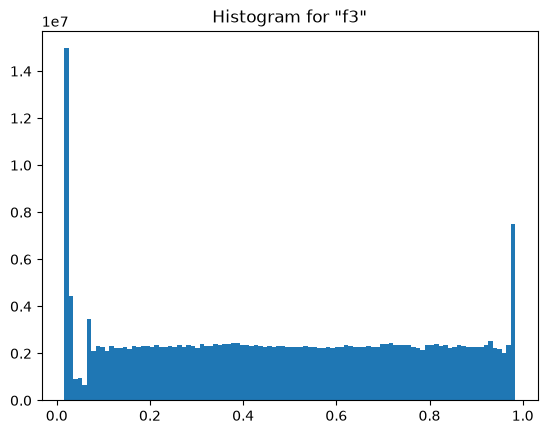

  1%|▍                                                  | 25114/3151208 [00:00<00:25, 122678.66it/s]

Found different values for "f4" for item 68574619: old one is 0.8753819465637207 and new one is 0.8753113746643066


100%|█████████████████████████████████████████████████| 3151208/3151208 [00:26<00:00, 119304.69it/s]


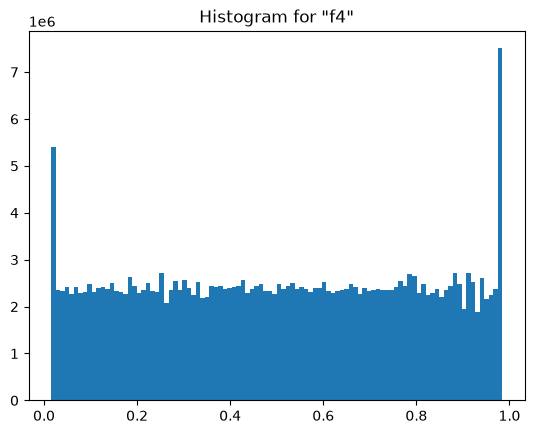

  1%|▍                                                  | 25672/3151208 [00:00<00:25, 123880.95it/s]

Found different values for "f5" for item 68574619: old one is 0.09599447250366211 and new one is 0.09455427527427673


100%|█████████████████████████████████████████████████| 3151208/3151208 [00:25<00:00, 123641.26it/s]


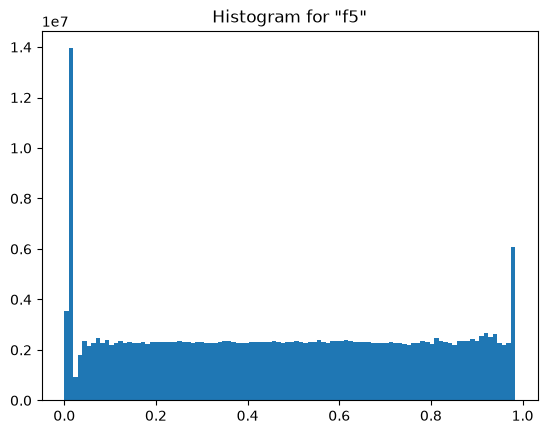

In [9]:
for f_name in BIN_FEATURES:
    item_values = []
    item_map = {}
    is_warning_shown = False
    for row in tqdm(df.itertuples(index=False), total=len(df), ncols=100):
        for iid, f_val in zip(row.item_id, getattr(row, f_name)):
            if not is_warning_shown:
                if iid in item_map:
                    if f_val != item_map[iid]:
                        print(
                            f"Found different values for \"{f_name}\" for item {iid}: "
                            f"old one is {f_val} and new one is {item_map[iid]}"
                        )
                        is_warning_shown = True
                else:
                    item_map[iid] = f_val
            item_values.append(f_val)
    plt.hist(np.asarray(item_values), bins=100)
    plt.title(f"Histogram for \"{f_name}\"")
    plt.show()
del item_values, item_map

In [10]:
def unfold_candidates(cand_df, cand_cols):
    array_dict = {}
    for f_name in cand_cols:
        item_values = []
        for _, f_arr in cand_df[f_name].items():
            item_values += f_arr.tolist()
        array_dict[f_name] = np.asarray(item_values)
    del item_values
    out_df = pd.DataFrame(data=array_dict)
    del array_dict
    return out_df

In [11]:
sample_frac = 0.1  # it is not enough memory to load all features at the same time

sample_df = unfold_candidates(df[BIN_FEATURES].sample(frac=sample_frac), BIN_FEATURES)

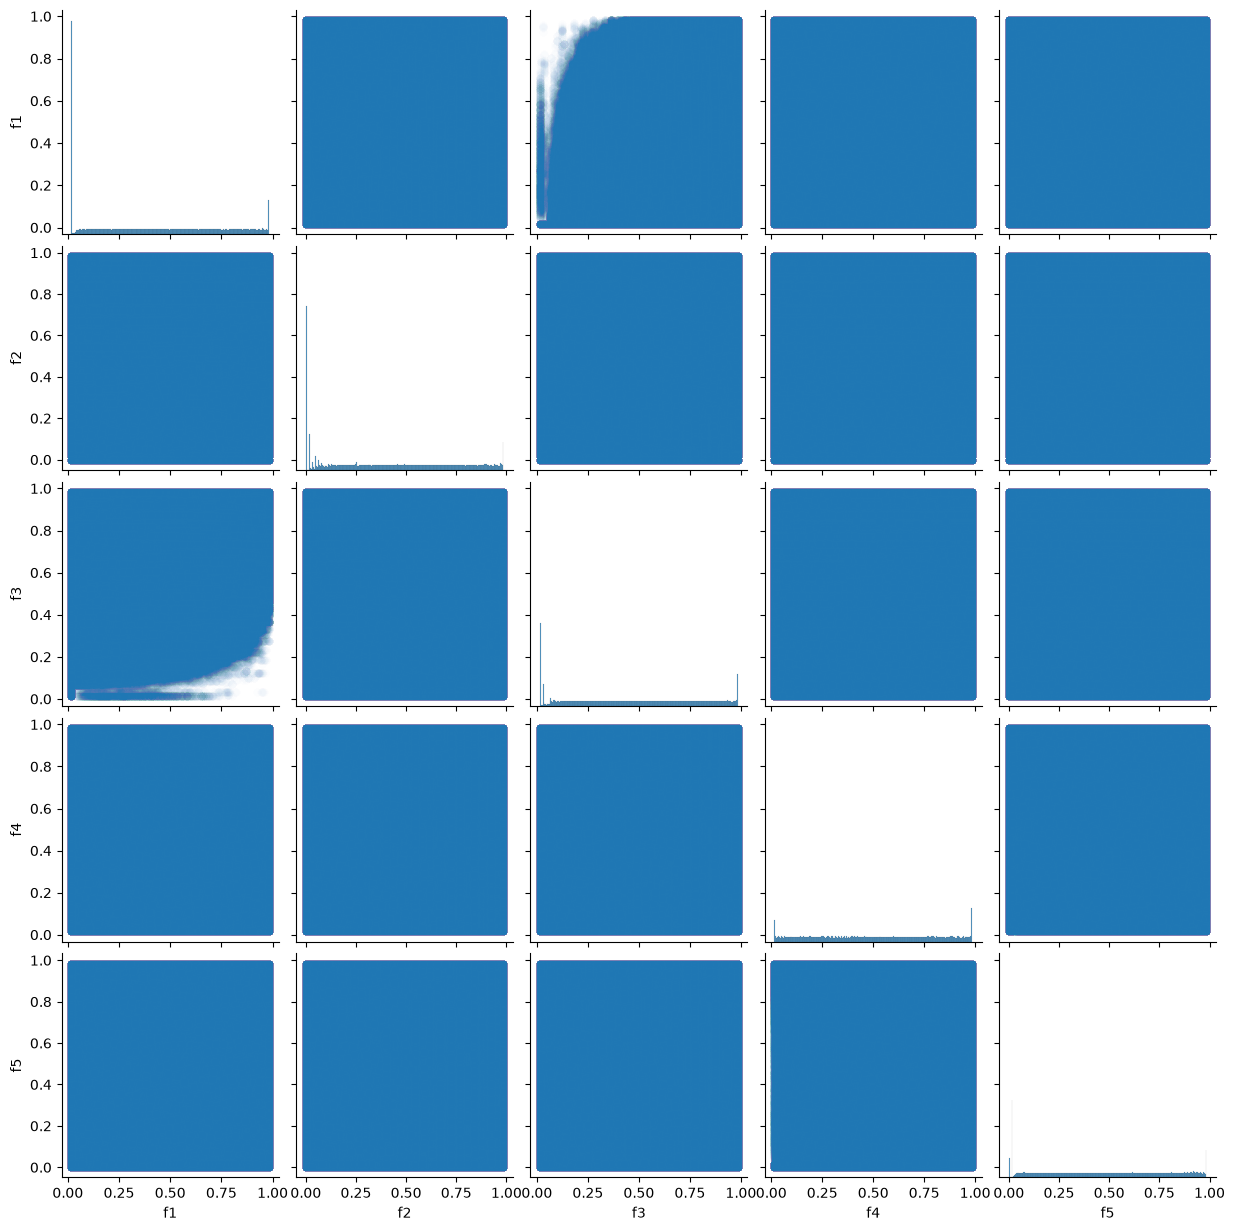

In [12]:
sns.pairplot(sample_df, plot_kws={"alpha": 0.01})
plt.show()

In [13]:
del sample_df
plt.close()
gc.collect()

6228

## Check balance of target

In [14]:
TARG_TST_FEATURES = ["category_id", "target", "item_id"]

In [15]:
split = DATA_PATH / "competition" / "train"
content_list = [
    pd.read_parquet(f, columns=TARG_TST_FEATURES)
    for f in sorted(split.glob("impressions/part-*.parquet"))
]
df = pd.concat(content_list, axis=0, ignore_index=True)
del content_list

In [16]:
sample_frac = 0.1  # it is not enough memory to load all features at the same time

sample_df = unfold_candidates(df[TARG_TST_FEATURES].sample(frac=sample_frac), TARG_TST_FEATURES)

In [17]:
print(f"Percent of zero targets: {(100*len(sample_df.loc[sample_df["target"] == 0]))/len(sample_df)}%")

Percent of zero targets: 97.79463158152785%
